In [110]:
from pathlib import Path

import numpy as np
import pandas as pd

from skimage.io import imread
from skimage.measure import label, regionprops

from scipy.ndimage import gaussian_filter, gaussian_laplace
from skimage.filters import sobel

from matplotlib import pyplot as plt

### In this notebook, we calculate the mean/std/distributions of sizes of the 3 classes: granule, tail, spike

In [2]:
data_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images")
labels_dir = data_dir / "labels"
images_dir = data_dir / "rare_granules"

In [ ]:
labels_dict = {
    1: "granule",
    2: "tail",
    3: "spike"
}

In [3]:
[p for p in data_dir.iterdir() if p.is_dir()]

[PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images/labels'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images/rare_granules'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images/2951'),
 PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images/annotations_rare_granules')]

In [65]:
names_to_exclude = ["40135_J5_new_x4300_-10um_0002.png",
                    "40135_G1_x4300_-10um_0095.png"]

filenames = []
for file in labels_dir.glob("*.png"):
    if file.name in names_to_exclude:
        continue
    filenames.append(file.name)

filenames

['40135_E1_x4300_-10um_0013.png',
 '40135_J5_new_x4300_-10um_0081.png',
 '40135_G1_x4300_-10um_0002.png',
 '40135_G1_x4300_-10um_0101.png',
 '40135_E4_new_x4300_-10um_0053.png',
 '40135_E4_new_x4300_-10um_0023.png',
 '40135_G1_x4300_-10um_0093.png',
 '40135_E4_new_x4300_-10um_0044.png',
 '40135_E4_new_x4300_-10um_0064.png',
 '40135_E4_new_x4300_-10um_0021.png',
 '40135_G1_x4300_-10um_0033.png',
 '40135-B5_x4300_-10um_0025.png',
 '40135_G1_x4300_-10um_0024.png',
 '40135_E4_new_x4300_-10um_0029.png',
 '40135_E4_new_x4300_-10um_0001.png',
 '40135_G1_x4300_-10um_0091.png',
 '40135_E4_new_x4300_-10um_0097.png',
 '40135_E4_new_x4300_-10um_0027.png',
 '40135_G1_x4300_-10um_0027.png',
 '40135_E4_new_x4300_-10um_0082.png',
 '40135_G1_x4300_-10um_0018.png']

In [66]:
def get_region_characteristics(labels_dir):

    sizes_dict = {}
    axes_dict = {}

    for f in list(labels_dir.glob("*.png")):
        file = f.name
        labels = imread(f"{labels_dir}/{file}")

        for class_value in np.unique(labels):
            if class_value == 0:
                continue

            binary = labels == class_value
            connected = label(binary)

            for region in regionprops(connected):

                # find the area of the regions
                sizes_dict.setdefault(class_value, []).append(region.area)

                # find the major and minor axes
                axes_dict.setdefault(
                    class_value,
                    {"major": [], "minor": []}
                )
        
                axes_dict[class_value]["major"].append(region.axis_major_length)
                axes_dict[class_value]["minor"].append(region.axis_minor_length)

    return sizes_dict, axes_dict

In [67]:
sizes, axes = get_region_characteristics(labels_dir)

In [68]:
stats = {}

for key in sizes:
    class_name = labels_dict[key]

    stats[class_name] = {
        "area": {
            "mean": float(np.mean(sizes[key])),
            "std": float(np.std(sizes[key])),
        },
        "major": {
            "mean": float(np.mean(axes[key]["major"])),
            "std": float(np.std(axes[key]["major"])),
        },
        "minor": {
            "mean": float(np.mean(axes[key]["minor"])),
            "std": float(np.std(axes[key]["minor"])),
        },
    }

stats

{'granule': {'area': {'mean': 3023.387755102041, 'std': 1424.5535042183128},
  'major': {'mean': 61.7378022513564, 'std': 14.393787620831342},
  'minor': {'mean': 59.261608845675234, 'std': 13.969764691541528}},
 'tail': {'area': {'mean': 5164.75, 'std': 1701.2770460745069},
  'major': {'mean': 135.5374821410419, 'std': 32.46597350297029},
  'minor': {'mean': 53.49986584526819, 'std': 11.57409858121953}},
 'spike': {'area': {'mean': 3468.222222222222, 'std': 827.2504360534465},
  'major': {'mean': 70.23458449459747, 'std': 8.674841306071444},
  'minor': {'mean': 62.524790022941524, 'std': 8.480135598165038}}}

In [69]:
stats['tail']

{'area': {'mean': 5164.75, 'std': 1701.2770460745069},
 'major': {'mean': 135.5374821410419, 'std': 32.46597350297029},
 'minor': {'mean': 53.49986584526819, 'std': 11.57409858121953}}

## Testing

In [5]:
file = filenames[0]
file

'40135_E1_x4300_-10um_0013.png'

In [6]:
labels = imread(f"{labels_dir}/{file}")
img = imread(f"{images_dir}/{file}")

In [7]:
labels.shape, img.shape

((4096, 4096), (4096, 4096))

In [8]:
labels.dtype, img.dtype

(dtype('uint8'), dtype('uint16'))

In [9]:
np.unique(labels)

array([0, 1, 2, 3], dtype=uint8)

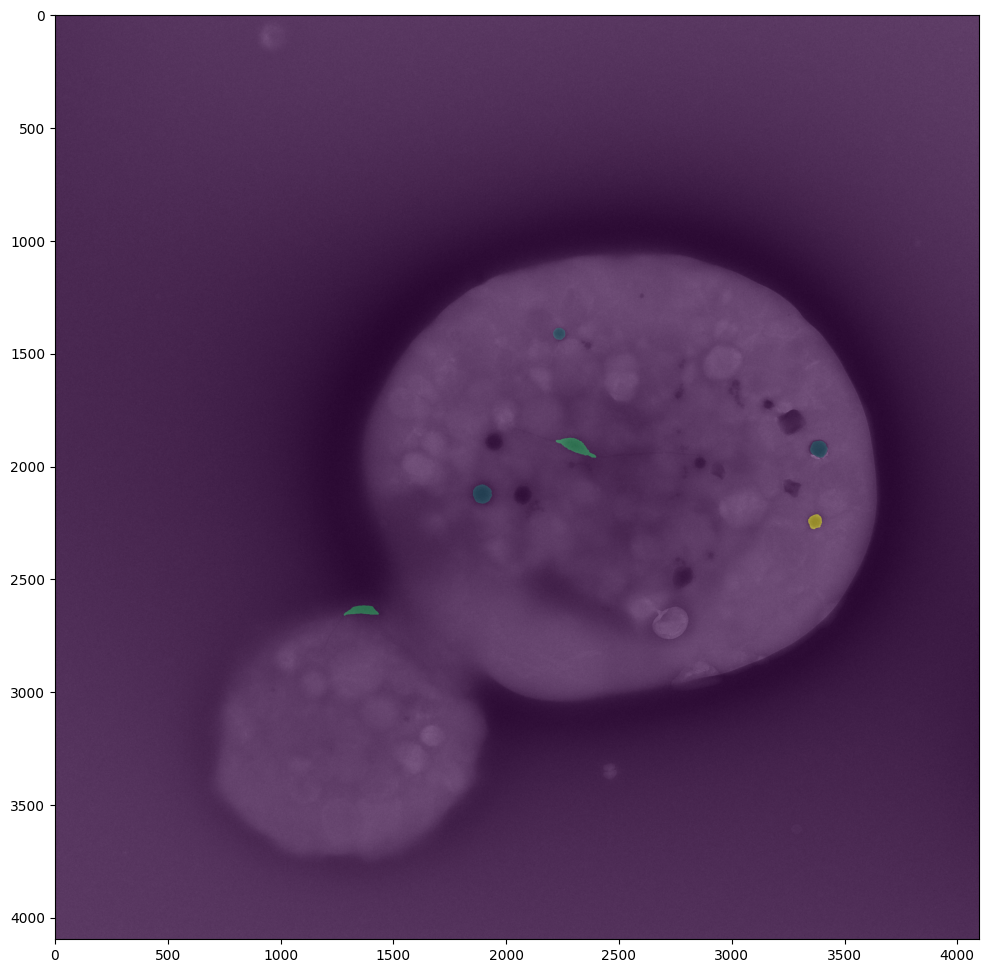

In [11]:
plt.figure(figsize=(12, 12))

plt.imshow(img, cmap='gray')
plt.imshow(labels, vmin=0, vmax=3, alpha=0.5)

plt.show()

In [12]:
sizes_dict = {1: [], 2: [], 3: []}
sizes_dict = {}

In [17]:
sizes_dict = {}
axes_dict = {}

for class_value in np.unique(labels):
    if class_value == 0:
        continue

    binary = labels == class_value
    connected = label(binary)

    for region in regionprops(connected):
        sizes_dict.setdefault(class_value, []).append(region.area)

        axes_dict.setdefault(
            class_value,
            {"major": [], "minor": []}
        )

        axes_dict[class_value]["major"].append(region.axis_major_length)
        axes_dict[class_value]["minor"].append(region.axis_minor_length)

In [18]:
sizes_dict

{np.uint8(1): [np.float64(2273.0), np.float64(4409.0), np.float64(5581.0)],
 np.uint8(2): [np.float64(6704.0), np.float64(4454.0)],
 np.uint8(3): [np.float64(3074.0)]}

In [19]:
axes_dict

{np.uint8(1): {'major': [54.383910162178324,
   77.31650798671863,
   85.29706414408582],
  'minor': [53.27973612391292, 72.89673873382964, 83.46126291257829]},
 np.uint8(2): {'major': [170.59209634172367, 151.42171135479046],
  'minor': [54.520083720070325, 43.079975580051126]},
 np.uint8(3): {'major': [66.30488547921657], 'minor': [59.49989397031335]}}

In [75]:
file = '40135_E4_new_x4300_-10um_0044.png'  # chosen as it has both tails and spikes

In [76]:
img = imread(images_dir / file)
labels = imread(labels_dir / file)

In [77]:
# TODO: get the pixel bounds of the cell so that you can do a crop prior to filtering
df = pd.read_csv(images_dir / "rare_granules_raw_correct.csv")

In [78]:
df

,dataset_id,image name,image id,pixel size,pixel unit,class name,color,x topleft pixels,y topleft pixels,width pixels,height pixels
0,2251,40135_E4_new_x4300_-10um_0001.ome.tif,20133,3.224048,NANOMETER,granule,-65281,2757.000000,2185.500000,67.500000,84.000000
1,2251,40135_E4_new_x4300_-10um_0001.ome.tif,20133,3.224048,NANOMETER,granule,-65281,2082.000000,1830.000000,64.500000,82.500000
2,2251,40135_E4_new_x4300_-10um_0001.ome.tif,20133,3.224048,NANOMETER,granule,-65281,1638.000000,1687.500000,58.500000,64.500000
3,2251,40135_E4_new_x4300_-10um_0001.ome.tif,20133,3.224048,NANOMETER,granule,-65281,1596.000000,2430.000000,69.000000,84.000000
4,2251,40135_E4_new_x4300_-10um_0001.ome.tif,20133,3.224048,NANOMETER,granule,-65281,1686.000000,2589.000000,51.000000,55.500000
...,...,...,...,...,...,...,...,...,...,...,...
137,1226,40135_G1_x4300_-10um_0024.ome.tiff,15653,3.224048,NANOMETER,granule,-65281,2104.172007,2793.278152,53.604974,57.131644
138,1226,40135_G1_x4300_-10um_0024.ome.tiff,15653,3.224048,NANOMETER,cell,11927551,1509.990307,1633.321057,1142.432364,1402.076173
139,1226,40135_G1_x4300_-10um_0024.ome.tiff,15653,3.224048,NANOMETER,spike,-1744764929,1937.600000,2231.250000,67.375000,56.350000
140,1226,40135_G1_x4300_-10um_0002.ome.tiff,15686,3.224048,NANOMETER,spike,-1744764929,2690.636123,1803.488251,53.077224,75.824605


In [79]:
df.loc[0, 'image name'].split('.')[0]

'40135_E4_new_x4300_-10um_0001'

In [80]:
df_cells = df[
    df["image name"].str.replace(r"\.ome\.tiff?$", "", regex=True) == file.removesuffix(".png")
]

In [81]:
df_cells

,dataset_id,image name,image id,pixel size,pixel unit,class name,color,x topleft pixels,y topleft pixels,width pixels,height pixels
25,2251,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,granule,-65281,1306.00,2376.00,74.0,80.00
26,2251,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,granule,-65281,658.00,2654.00,84.0,82.00
27,2251,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,tail,-1744764929,1006.00,2308.00,110.0,108.00
28,2251,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,cell,11927551,528.75,2036.25,1732.5,1406.25
29,2251,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,tail,-1744764929,1361.25,2886.25,77.5,66.25
90,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,granule,-65281,1306.00,2376.00,74.0,80.00
91,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,granule,-65281,658.00,2654.00,84.0,82.00
92,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,tail,-1744764929,1006.00,2308.00,110.0,108.00
93,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,cell,11927551,528.75,2036.25,1732.5,1406.25
94,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,spike,-1744764929,1361.25,2886.25,77.5,66.25


In [82]:
columns = ['x topleft pixels', 'y topleft pixels', 'width pixels', 'height pixels']
df_cells = df_cells.drop_duplicates(subset=columns, keep='last')
df_cells

,dataset_id,image name,image id,pixel size,pixel unit,class name,color,x topleft pixels,y topleft pixels,width pixels,height pixels
90,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,granule,-65281,1306.00,2376.00,74.0,80.00
91,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,granule,-65281,658.00,2654.00,84.0,82.00
92,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,tail,-1744764929,1006.00,2308.00,110.0,108.00
93,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,cell,11927551,528.75,2036.25,1732.5,1406.25
94,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,spike,-1744764929,1361.25,2886.25,77.5,66.25


In [83]:
df_cells = df_cells[df_cells['class name'] == 'cell']
df_cells

,dataset_id,image name,image id,pixel size,pixel unit,class name,color,x topleft pixels,y topleft pixels,width pixels,height pixels
93,1226,40135_E4_new_x4300_-10um_0044.ome.tif,20109,3.224048,NANOMETER,cell,11927551,528.75,2036.25,1732.5,1406.25


In [84]:
x_tl = round(df_cells["x topleft pixels"].iloc[0])
y_tl = round(df_cells["y topleft pixels"].iloc[0])
w = round(df_cells["width pixels"].iloc[0])
h = round(df_cells["height pixels"].iloc[0])

In [85]:
x_tl, y_tl, w, h

(529, 2036, 1732, 1406)

In [ ]:
# Function to go through all the filenames, extract their cell bounds in a list, then make crops from the image and labels.
# After that the pixel feature extractor will be run on the crops

def crop_extractor(filenames, images_dir, labels_dir, csv_name):

    df = pd.read_csv(images_dir / csv_name)
    columns = ['x topleft pixels', 'y topleft pixels', 'width pixels', 'height pixels']

    crops_dict = {}

    for file in filenames:

        print(file)
        img_crops = []
        label_crops = []
        img = imread(images_dir / file)
        labels = imread(labels_dir / file)

        df_cells = df[
            df["image name"].str.replace(r"\.ome\.tiff?$", "", regex=True) == file.removesuffix(".png")
        ]

        df_cells = df_cells.drop_duplicates(subset=columns, keep='last')
        df_cells = df_cells[df_cells['class name'] == 'cell']

        for _, row in df_cells.iterrows():
            x_tl = round(row["x topleft pixels"])
            y_tl = round(row["y topleft pixels"])
            w = round(row["width pixels"])
            h = round(row["height pixels"])

            if h > 500 and w > 500:
                img_crops.append(img[y_tl:y_tl + h, x_tl:x_tl + w])
                label_crops.append(labels[y_tl:y_tl + h, x_tl:x_tl + w])

        crops_dict[file] = {'img_crops': img_crops, 'label_crops': label_crops}

        del img, labels
        break

    return crops_dict

In [105]:
csv_name = "rare_granules_raw_correct.csv"
crops = crop_extractor(filenames, images_dir, labels_dir, csv_name)

40135_E1_x4300_-10um_0013.png


In [107]:
crops.keys()

dict_keys(['40135_E1_x4300_-10um_0013.png'])

In [108]:
crops['40135_E1_x4300_-10um_0013.png'].keys()

dict_keys(['img_crops', 'label_crops'])

In [109]:
for key, value in crops['40135_E1_x4300_-10um_0013.png'].items():
    print(len(value))

2
2


In [111]:
def extract_pixel_features(
    image,
    labels,
    stats,
    sigma_fractions=(0.10, 0.20, 0.35),
    truncate=4.0,
):
    """
    Extract multiscale features for pixel classification.

    Features at each sigma:
        - Gaussian-smoothed intensity
        - Sobel edge magnitude
        - Laplacian of Gaussian
        - Hessian eigenvalue 1
        - Hessian eigenvalue 2

    Raw image intensity is also included.

    Parameters
    ----------
    image : np.ndarray, shape (Y, X)
        Grayscale image.

    labels : np.ndarray, shape (Y, X)
        Pixel-wise class labels.

    stats : dict
        Dictionary containing class statistics, e.g.
        stats[class_name]["minor"]["mean"].

    sigma_fractions : tuple
        Fractions of the characteristic object width used for sigma.

    truncate : float
        Radius of Gaussian kernel in units of sigma.
        scipy's normal default is 4 sigma.

    Returns
    -------
    feature_map : np.ndarray
        Shape (Y, X, C).

    data : np.ndarray
        Shape (Y*X, C+1).
        Each row corresponds to one pixel.
        Final column contains its label.

    feature_names : list
        Name of each feature channel.

    sigmas : np.ndarray
        Sigma values used.

    kernel_sizes : np.ndarray
        Approximate kernel size corresponding to each sigma.
    """

    image = np.asarray(image, dtype=np.float32)
    labels = np.asarray(labels)

    if image.ndim != 2:
        raise ValueError("image must be a 2D grayscale image")

    if labels.shape != image.shape:
        raise ValueError("image and labels must have the same shape")

    # ------------------------------------------------------------
    # 1. Determine characteristic object width
    # ------------------------------------------------------------

    minor_means = np.array([
        class_stats["minor"]["mean"]
        for class_stats in stats.values()
    ])

    # Median makes this less influenced by one unusually wide class.
    characteristic_width = np.median(minor_means)

    # ------------------------------------------------------------
    # 2. Choose sigma values
    # ------------------------------------------------------------

    sigmas = characteristic_width * np.asarray(sigma_fractions)

    # Corresponding Gaussian kernel sizes.
    #
    # Radius = truncate * sigma
    # Width = 2 * radius + 1
    #
    kernel_sizes = (
        2 * np.ceil(truncate * sigmas).astype(int) + 1
    )

    # ------------------------------------------------------------
    # 3. Build feature map
    # ------------------------------------------------------------

    features = []
    feature_names = []

    # Raw intensity
    features.append(image)
    feature_names.append("intensity")

    for sigma in sigmas:

        # ---------- Gaussian ----------
        gaussian = gaussian_filter(
            image,
            sigma=sigma,
            truncate=truncate,
        )

        features.append(gaussian)
        feature_names.append(f"gaussian_sigma_{sigma:.2f}")

        # ---------- Sobel ----------
        #
        # Sobel is applied after smoothing so that the edge measurement
        # corresponds to the selected spatial scale.
        sobel_feature = sobel(gaussian)

        features.append(sobel_feature)
        feature_names.append(f"sobel_sigma_{sigma:.2f}")

        # ---------- Laplacian of Gaussian ----------
        log_feature = gaussian_laplace(
            image,
            sigma=sigma,
            truncate=truncate,
        )

        # Scale normalization makes responses at different sigma
        # values more comparable.
        log_feature = (sigma ** 2) * log_feature

        features.append(log_feature)
        feature_names.append(f"LoG_sigma_{sigma:.2f}")

        # ---------- Hessian ----------
        #
        # Second derivatives of the Gaussian-smoothed image.
        Hyy = gaussian_filter(
            image,
            sigma=sigma,
            order=(2, 0),
            truncate=truncate,
        )

        Hxy = gaussian_filter(
            image,
            sigma=sigma,
            order=(1, 1),
            truncate=truncate,
        )

        Hxx = gaussian_filter(
            image,
            sigma=sigma,
            order=(0, 2),
            truncate=truncate,
        )

        # Scale-normalize second derivatives
        Hxx *= sigma ** 2
        Hxy *= sigma ** 2
        Hyy *= sigma ** 2

        # Eigenvalues of a symmetric 2x2 Hessian matrix:
        #
        # [Hxx Hxy]
        # [Hxy Hyy]
        #
        trace = Hxx + Hyy
        difference = Hxx - Hyy

        root = np.sqrt(
            difference ** 2 +
            4 * Hxy ** 2
        )

        eig1 = (trace + root) / 2
        eig2 = (trace - root) / 2

        features.append(eig1)
        feature_names.append(f"hessian_eig1_sigma_{sigma:.2f}")

        features.append(eig2)
        feature_names.append(f"hessian_eig2_sigma_{sigma:.2f}")

    # ------------------------------------------------------------
    # 4. Stack into (Y, X, C)
    # ------------------------------------------------------------

    feature_map = np.stack(features, axis=-1)

    # ------------------------------------------------------------
    # 5. Convert pixels into rows
    # ------------------------------------------------------------

    n_features = feature_map.shape[-1]

    X = feature_map.reshape(-1, n_features)
    y = labels.reshape(-1, 1)

    # Last column = label
    data = np.concatenate((X, y), axis=1)

    return feature_map, data, feature_names, sigmas, kernel_sizes